# Insurance Charges Prediction — Linear Regression Case Study

## Business Problem
An insurance company wants to estimate the annual medical **charges** a policyholder is likely to incur, 
based on demographic and health-related attributes (age, BMI-related fields, smoking status, region, 
claim history, etc.). Accurate charge prediction supports:
- Risk-based premium pricing
- Identifying high-cost customer segments
- Flagging outlier claims for review

**Target variable:** `charges` (continuous, USD)

**Success metrics:**
- **R² / Adjusted R²** — proportion of variance explained
- **MAE** — average dollar error (business-interpretable)
- **RMSE** — penalizes large errors more heavily (relevant since high-cost claims are business-critical)

We will also inspect **residuals** and **coefficients**, since a linear regression model is only as 
trustworthy as its assumptions (linearity, homoscedasticity, no severe multicollinearity) and its 
interpretability is one of its biggest selling points over black-box models.


In [1]:
# Core libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.stats import skew

# Modeling
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.dummy import DummyRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
from statsmodels.stats.outliers_influence import variance_inflation_factor

sns.set_style('whitegrid')
pd.set_option('display.max_columns', None)


In [3]:
# Load the dataset
file_path = r"C:\Users\jeevi\Downloads\data_files\insurance.csv"
df = pd.read_csv(file_path)
df.head()


,age,sex,bmi,children,smoker,Claim_Amount,past_consultations,num_of_steps,Hospital_expenditure,NUmber_of_past_hospitalizations,Anual_Salary,region,charges
0,18.0,male,23.21,0.0,no,29087.54313,17.0,715428.0,4720920.992,0.0,55784970.05,southeast,1121.8739
1,18.0,male,30.14,0.0,no,39053.67437,7.0,699157.0,4329831.676,0.0,13700885.19,southeast,1131.5066
2,18.0,male,33.33,0.0,no,39023.62759,19.0,702341.0,6884860.774,0.0,73523107.27,southeast,1135.9407
3,18.0,male,33.66,0.0,no,28185.39332,11.0,700250.0,4274773.550,0.0,75819679.60,southeast,1136.3994
4,18.0,male,34.10,0.0,no,14697.85941,16.0,711584.0,3787293.921,0.0,23012320.01,southeast,1137.0110


## 1. Exploratory Data Analysis (EDA)

In [4]:
# Structural overview: dtypes, non-null counts, memory footprint
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 13 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   age                              1329 non-null   float64
 1   sex                              1338 non-null   object 
 2   bmi                              1335 non-null   float64
 3   children                         1333 non-null   float64
 4   smoker                           1338 non-null   object 
 5   Claim_Amount                     1324 non-null   float64
 6   past_consultations               1332 non-null   float64
 7   num_of_steps                     1335 non-null   float64
 8   Hospital_expenditure             1334 non-null   float64
 9   NUmber_of_past_hospitalizations  1336 non-null   float64
 10  Anual_Salary                     1332 non-null   float64
 11  region                           1338 non-null   object 
 12  charges             

In [5]:
# Statistical summary of numeric columns
df.describe()


,age,bmi,children,Claim_Amount,past_consultations,num_of_steps,Hospital_expenditure,NUmber_of_past_hospitalizations,Anual_Salary,charges
count,1329.000000,1335.000000,1333.000000,1324.000000,1332.000000,1.335000e+03,1.334000e+03,1336.000000,1.332000e+03,1338.000000
mean,39.310008,30.665112,1.090773,33361.327180,15.216216,9.100047e+05,1.584179e+07,1.060629,3.696849e+08,13270.422265
std,14.034818,6.101690,1.201856,15617.288337,7.467723,9.188612e+04,2.669305e+07,0.533583,5.668843e+08,12110.011237
min,18.000000,15.960000,0.000000,1920.136268,1.000000,6.954300e+05,2.945253e+04,0.000000,2.747072e+06,1121.873900
25%,27.000000,26.302500,0.000000,20768.860390,9.000000,8.471995e+05,4.077633e+06,1.000000,7.701932e+07,4740.287150
50%,39.000000,30.400000,1.000000,33700.310675,15.000000,9.143000e+05,7.490337e+06,1.000000,1.419361e+08,9382.033000
75%,51.000000,34.687500,2.000000,45052.331957,20.000000,9.716840e+05,1.084082e+07,1.000000,3.243499e+08,16639.912515
max,64.000000,53.130000,5.000000,77277.988480,40.000000,1.107872e+06,2.616317e+08,3.000000,4.117197e+09,63770.428010


#### Observations:
- Missing Values are present in multiple numerical columns while target variable (charges) contain no missing values.
- Age is symmetrically distributed with values ranging from 18 to 64.
- Number of children ranges from 0 to 5, with most individuals having one child.
- Extreme BMI may represent outliers and should be represented using boxplots.
- Claim Amount appears reasonably distributed with moderate variability.
- Past consultations are centered around 15 visits, with values ranging from 1 to 40.
- Number of steps appears approximately symmetric with moderate variability.
- Hospital expenditure is positively skewed  with a few individuals having exceptionally high expenses.
- Most individuals have approximately one previous hospitalization.
- Annual Salary exhibits substantial positive skewness with extremely large salary values indicating possible outliers.
- Insurance charges are positively skewed,indicating that a small number of individuals incur significantly higher medical costs.

### 1.1 Target distribution
Insurance charges are almost always **right-skewed** in real-world data (a small number of very 
high-cost claims). Linear regression assumes roughly normal, homoscedastic residuals, so an 
unexamined skewed target is one of the most common reasons a linear model underperforms. 
We check this *before* we build anything.

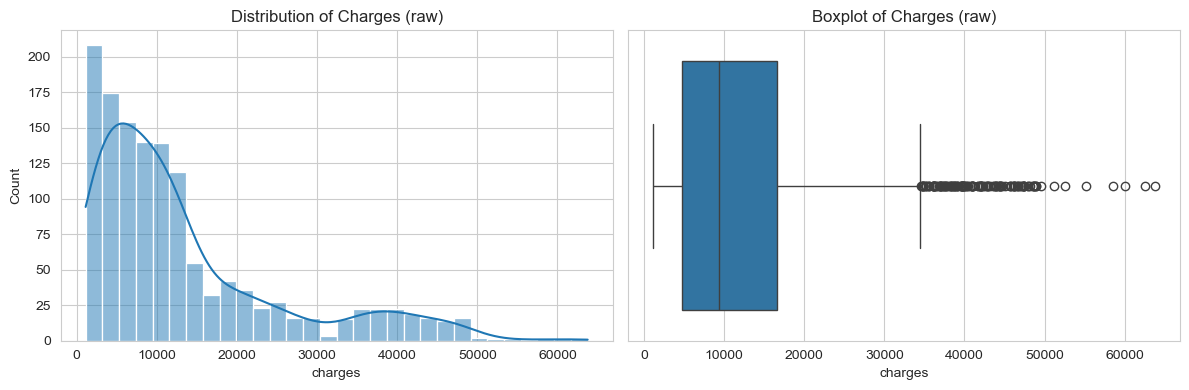

Skewness of charges: 1.5141797118745743


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df['charges'], kde=True, ax=axes[0])
axes[0].set_title('Distribution of Charges (raw)')

sns.boxplot(x=df['charges'], ax=axes[1])
axes[1].set_title('Boxplot of Charges (raw)')
plt.tight_layout()
plt.show()

print("Skewness of charges:", skew(df['charges']))


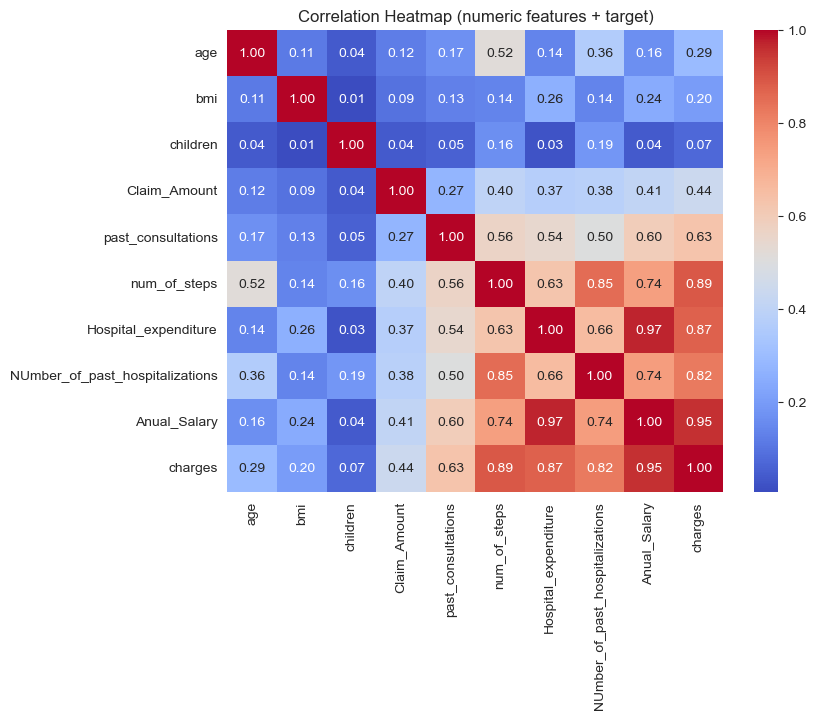

In [7]:
# Correlation of numeric features WITH the target 
plt.figure(figsize=(8, 6))
sns.heatmap(df.corr(numeric_only=True), annot=True, fmt='.2f', cmap='coolwarm')
plt.title('Correlation Heatmap (numeric features + target)')
plt.show()


#### Observations:
- The target variable(charges) has very strong positive correlation with various features.
- Several predictor variables are extremely highly correlated with each other which indicates multicollinearity.
- Features like children, bmi, and Claim_Amount contribute relatively little compared to salary and hospital expenditures.

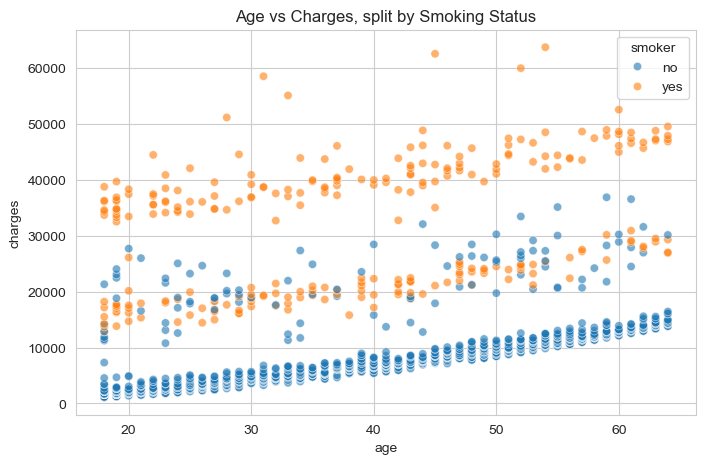

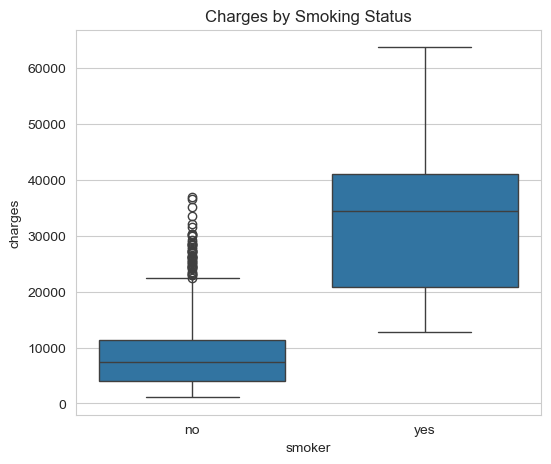

In [8]:
# Interaction check: does the age-charges relationship differ by smoking status?
plt.figure(figsize=(8, 5))
sns.scatterplot(x='age', y='charges', hue='smoker', data=df, alpha=0.6)
plt.title('Age vs Charges, split by Smoking Status')
plt.show()

plt.figure(figsize=(6, 5))
sns.boxplot(x='smoker', y='charges', data=df)
plt.title('Charges by Smoking Status')
plt.show()


#### Observations:
**1. Age vs Charges, split by Smoking Status**
   - Across all categories, medical charges consistently increase as age increases, showing a clear baseline linear relationship between aging and higher healthcare costs.
   - Smokers (smoker = yes, orange dots) generally incur substantially higher charges than non-smokers (smoker = no, blue dots) at almost every age level.
   - The data forms three noticeable bands:
      * Bottom band:Non-smokers with standard charges
      * Middle band:Non-smokers with higher medical needs combined with lower-cost smokers
      * Top band: Primary group of smokers experiencing severe high charges
        
**2. Charges by Smoking Status**
   - The median medical charge for smokers (around **\$35,000**) is drastically higher than the median for non-smokers (around **\$8,000**).

   - The Interquartile Range (IQR) for smokers is much wider (approximately **\$20,000** **to** **\$41,000**), indicating significantly greater variability in medical charges compared to non-smokers.

   - Non-smokers have a relatively compact distribution with numerous upper-bound outliers, where charges extend beyond **\$22,000** up to approximately **\$37,000**. In contrast, smokers do not exhibit individual high-value outliers because their entire distribution is shifted toward substantially higher medical charges.   

### 1.2 Data Cleaning: Nulls, Duplicates, Outliers

In [9]:
# Null counts per column
df.isnull().sum()


age                                 9
sex                                 0
bmi                                 3
children                            5
smoker                              0
Claim_Amount                       14
past_consultations                  6
num_of_steps                        3
Hospital_expenditure                4
NUmber_of_past_hospitalizations     2
Anual_Salary                        6
region                              0
charges                             0
dtype: int64

In [10]:
#Percentage of missing values
total_nulls = df.isnull().sum().sum()
pct_nulls = total_nulls / df.shape[0] * 100
print(f"Total null values: {total_nulls} ({pct_nulls:.2f}% of rows)")


Total null values: 52 (3.89% of rows)


**Before dropping**, check whether missingness looks random (MCAR) or systematic. 
If nulls are concentrated in a specific subgroup (e.g. mostly non-smokers), dropping them 
would bias the model toward the remaining group.

In [11]:
# Check missingness pattern against a key categorical column
rows_with_nulls = df[df.isnull().any(axis=1)]
if len(rows_with_nulls) > 0 and 'smoker' in df.columns:
    print("Smoker distribution among rows WITH nulls:")
    print(rows_with_nulls['smoker'].value_counts(normalize=True))
    print("\nSmoker distribution in full dataset:")
    print(df['smoker'].value_counts(normalize=True))
    


Smoker distribution among rows WITH nulls:
smoker
no     0.803922
yes    0.196078
Name: proportion, dtype: float64

Smoker distribution in full dataset:
smoker
no     0.795217
yes    0.204783
Name: proportion, dtype: float64


#### Observations:
The proportion of smokers and non-smokers among rows with missing values is almost the same as in the full dataset.
Missing values do not appear to be concentrated in either smokers or non-smokers.

In [12]:
# Nulls are a small share of rows (<5%) and appear randomly distributed across the smoker
# split above, so dropping them is unlikely to introduce systematic bias.
df = df.dropna()
df.isnull().sum()


age                                0
sex                                0
bmi                                0
children                           0
smoker                             0
Claim_Amount                       0
past_consultations                 0
num_of_steps                       0
Hospital_expenditure               0
NUmber_of_past_hospitalizations    0
Anual_Salary                       0
region                             0
charges                            0
dtype: int64

In [13]:
# Duplicate rows
print("Duplicate rows:", df.duplicated().sum())
df = df.drop_duplicates()


Duplicate rows: 0


**Outlier check.** We visualize outliers but we do **not** remove them, 
because they represent genuine high-cost cases rather than data entry errors. However, we now *quantify* this decision rather 
than only asserting it, using a z-score count.

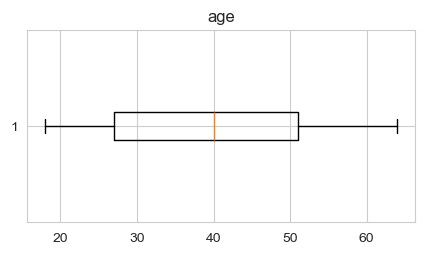

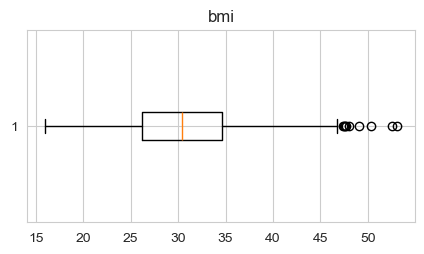

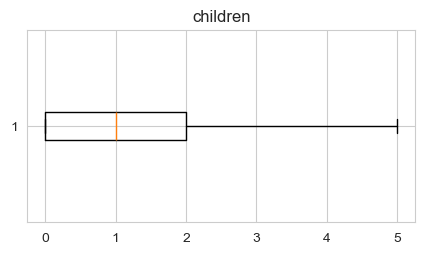

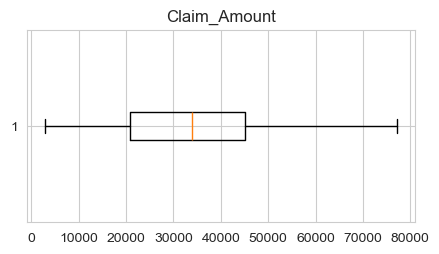

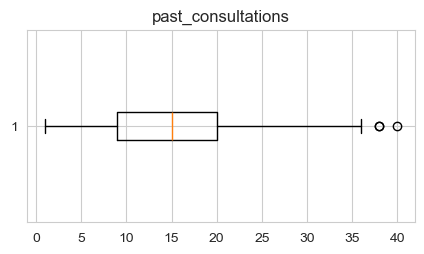

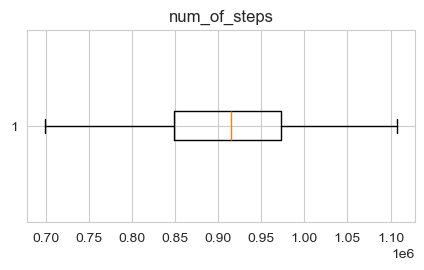

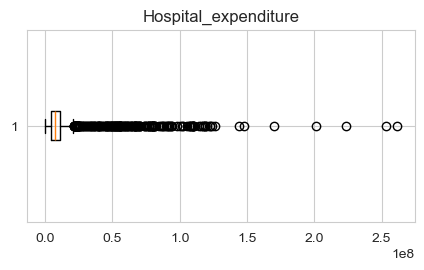

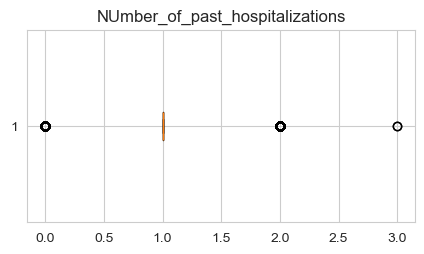

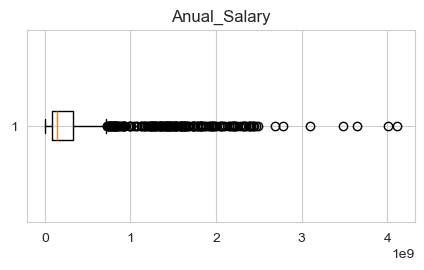

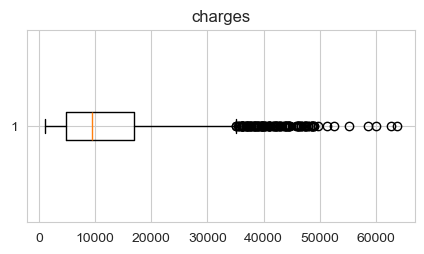

In [14]:
# Boxplots per numeric column
num_cols_all = [c for c in df.columns if df[c].dtype != 'object']
for c in num_cols_all:
    plt.figure(figsize=(5, 2.5))
    plt.boxplot(df[c], vert=False)
    plt.title(c)
    plt.show()


In [15]:
# Quantify how many extreme points (|z| > 3) exist per numeric column
z_scores = np.abs(stats.zscore(df[num_cols_all]))
outlier_counts = (z_scores > 3).sum(axis=0)
pd.Series(outlier_counts, index=num_cols_all, name='n_outliers (|z|>3)')


age                                 0
bmi                                 4
children                           16
Claim_Amount                        0
past_consultations                  3
num_of_steps                        0
Hospital_expenditure               34
NUmber_of_past_hospitalizations     2
Anual_Salary                       35
charges                             8
Name: n_outliers (|z|>3), dtype: int64

**Decision:** outliers are retained. They represent genuine high-cost insurance cases 
(expensive treatments, high claim amounts, high hospital expenditure). Removing them would 
strip out exactly the extreme-but-valid patterns the business most needs the model to capture 
(e.g. flagging likely high-cost policyholders). The z-score check above confirms these are a 
small minority of rows, not a data-entry problem dominating the dataset.

## 2. Multicollinearity Check (VIF)

In [16]:
def calc_vif(dataframe, exclude=('charges',)):
    """Compute VIF for all numeric, non-excluded columns in `dataframe`."""
    cols = [c for c in dataframe.columns if dataframe[c].dtype != 'object' and c not in exclude]
    x = dataframe[cols]
    vif = pd.DataFrame()
    vif['Column Name'] = x.columns
    vif['VIF Value'] = [variance_inflation_factor(x.values, i) for i in range(len(x.columns))]
    return vif.sort_values('VIF Value', ascending=False).reset_index(drop=True)

calc_vif(df)


,Column Name,VIF Value
0,num_of_steps,60.555661
1,Anual_Salary,37.965843
2,Hospital_expenditure,27.435063
3,bmi,26.415705
4,NUmber_of_past_hospitalizations,17.696136
5,age,11.889264
6,past_consultations,8.586173
7,Claim_Amount,6.945681
8,children,1.957933


In [17]:
# Iteratively drop the single worst offender (VIF > 10) and recompute,
# rather than dropping several columns based on one snapshot of VIF values.
vif_table = calc_vif(df)
dropped_cols = []

while vif_table['VIF Value'].max() > 10:
    worst_col = vif_table.iloc[0]['Column Name']
    df = df.drop(columns=[worst_col])
    dropped_cols.append(worst_col)
    vif_table = calc_vif(df)

print("Columns dropped for multicollinearity (VIF > 10):", dropped_cols)
vif_table


Columns dropped for multicollinearity (VIF > 10): ['num_of_steps', 'Anual_Salary', 'NUmber_of_past_hospitalizations', 'bmi']


,Column Name,VIF Value
0,past_consultations,6.272636
1,age,5.753673
2,Claim_Amount,5.313145
3,Hospital_expenditure,1.891579
4,children,1.786858


All remaining numeric features now have VIF < 10, meaning no severe multicollinearity 
remains among them. These, plus the categorical features, form our final feature set.

## 3. Feature & Target Preparation

In [18]:
# Final feature set: everything except the target
feature_cols = [c for c in df.columns if c != 'charges']
X = df[feature_cols].copy()
y_raw = df['charges'].copy()
X.head()


,age,sex,children,smoker,Claim_Amount,past_consultations,Hospital_expenditure,region
0,18.0,male,0.0,no,29087.54313,17.0,4720920.992,southeast
1,18.0,male,0.0,no,39053.67437,7.0,4329831.676,southeast
2,18.0,male,0.0,no,39023.62759,19.0,6884860.774,southeast
3,18.0,male,0.0,no,28185.39332,11.0,4274773.550,southeast
4,18.0,male,0.0,no,14697.85941,16.0,3787293.921,southeast


### 3.1 Target transformation
`charges` is right-skewed (confirmed in section 1.1). We model `log1p(charges)` instead of 
raw charges so the residuals better satisfy linear regression's normality/homoscedasticity 
assumptions. We will invert the transform (`expm1`) whenever we need charges back in dollar terms 
(for MAE/RMSE reporting and for the final prediction function).

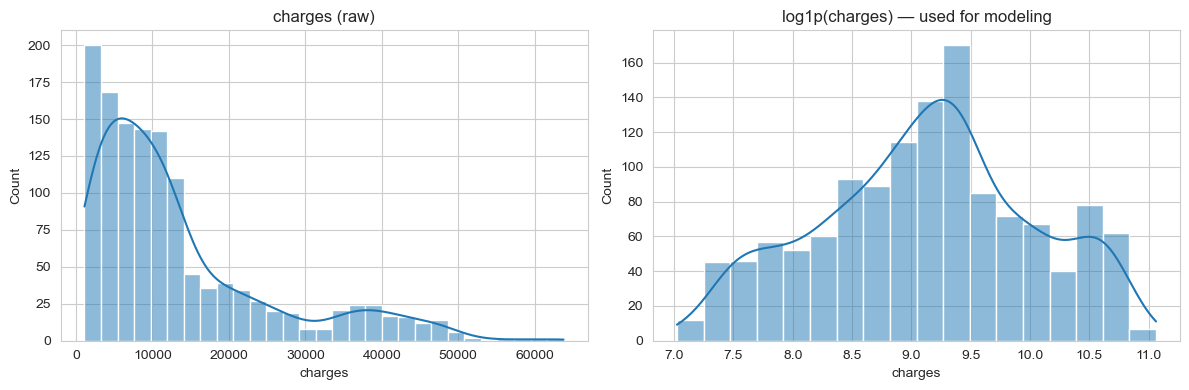

Skew before: 1.5066845429394624  | Skew after log1p: -0.09402942739636658


In [19]:
y = np.log1p(y_raw)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(y_raw, kde=True, ax=axes[0])
axes[0].set_title('charges (raw)')
sns.histplot(y, kde=True, ax=axes[1])
axes[1].set_title('log1p(charges) — used for modeling')
plt.tight_layout()
plt.show()

print("Skew before:", skew(y_raw), " | Skew after log1p:", skew(y))


### 3.2 Categorical encoding — one-hot, not label encoding
`sex`, `smoker`, and `region` are **nominal** categories with no inherent order. Using 
`LabelEncoder` here would assign arbitrary integers 
(e.g. region 0/1/2/3), which tells a linear model that "region 3" is quantitatively three times 
"region 1" — a false ordinal relationship that will distort the coefficients. 
`pd.get_dummies` avoids this. `drop_first=True` also avoids the dummy-variable trap 
(perfect multicollinearity between one-hot columns).

In [20]:
cat_cols = [c for c in X.columns if X[c].dtype == 'object']
print("Categorical columns to encode:", cat_cols)

X = pd.get_dummies(X, columns=cat_cols, drop_first=True)
X.head()


Categorical columns to encode: ['sex', 'smoker', 'region']


,age,children,Claim_Amount,past_consultations,Hospital_expenditure,sex_male,smoker_yes,region_northwest,region_southeast,region_southwest
0,18.0,0.0,29087.54313,17.0,4720920.992,True,False,False,True,False
1,18.0,0.0,39053.67437,7.0,4329831.676,True,False,False,True,False
2,18.0,0.0,39023.62759,19.0,6884860.774,True,False,False,True,False
3,18.0,0.0,28185.39332,11.0,4274773.550,True,False,False,True,False
4,18.0,0.0,14697.85941,16.0,3787293.921,True,False,False,True,False


## 4. Train/Test Split

In [21]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
print(X_train.shape, X_test.shape)


(1029, 10) (258, 10)


### 4.1 Feature scaling
Scaling is not required for Linear Regression predictions,but it makes feature coefficients easier to compare and prevents data leakage by fitting the scaler only on the training data.

In [22]:
scaler = StandardScaler()
num_cols = [c for c in X_train.columns if X_train[c].nunique() > 2]  # leave binary dummies unscaled

X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()
X_train_scaled[num_cols] = scaler.fit_transform(X_train[num_cols])   # fit ONLY on train
X_test_scaled[num_cols] = scaler.transform(X_test[num_cols])         # transform test with train's scaler


## 5. Model Building

In [23]:
# Baseline: predicts the mean every time. Any real model must beat this to justify itself.
dummy = DummyRegressor(strategy='mean').fit(X_train_scaled, y_train)
dummy_r2 = r2_score(y_test, dummy.predict(X_test_scaled))
print(f"Baseline (mean-predictor) R²: {dummy_r2:.4f}")


Baseline (mean-predictor) R²: -0.0012


In [24]:
# Linear Regression
lin_model = LinearRegression()
lin_model.fit(X_train_scaled, y_train)
y_pred_log = lin_model.predict(X_test_scaled)


In [25]:
# Ridge and Lasso as regularized alternatives — natural comparison given we just spent
# section 2 fighting multicollinearity; regularization is a second line of defense against it.
ridge_model = Ridge(alpha=1.0).fit(X_train_scaled, y_train)
lasso_model = Lasso(alpha=0.01).fit(X_train_scaled, y_train)

y_pred_ridge = ridge_model.predict(X_test_scaled)
y_pred_lasso = lasso_model.predict(X_test_scaled)


## 6. Model Evaluation

Use multiple metrics to evaluate the model. R² measures model performance, Adjusted R² considers the number of features, and MAE/RMSE show the prediction error in actual charges.

In [26]:
def evaluate(name, y_true_log, y_pred_log, n_features):
    y_true_dollars = np.expm1(y_true_log)
    y_pred_dollars = np.expm1(y_pred_log)

    r2 = r2_score(y_true_log, y_pred_log)
    n = len(y_true_log)
    adj_r2 = 1 - (1 - r2) * (n - 1) / (n - n_features - 1)
    mae = mean_absolute_error(y_true_dollars, y_pred_dollars)
    rmse = np.sqrt(mean_squared_error(y_true_dollars, y_pred_dollars))

    print(f"{name:>15} | R²: {r2:.4f} | Adj R²: {adj_r2:.4f} | MAE: ${mae:,.2f} | RMSE: ${rmse:,.2f}")
    return {'model': name, 'r2': r2, 'adj_r2': adj_r2, 'mae': mae, 'rmse': rmse}

results = []
results.append(evaluate("Baseline", y_test, dummy.predict(X_test_scaled), X_train_scaled.shape[1]))
results.append(evaluate("Linear Reg", y_test, y_pred_log, X_train_scaled.shape[1]))
results.append(evaluate("Ridge", y_test, y_pred_ridge, X_train_scaled.shape[1]))
results.append(evaluate("Lasso", y_test, y_pred_lasso, X_train_scaled.shape[1]))

results_df = pd.DataFrame(results)
results_df


       Baseline | R²: -0.0012 | Adj R²: -0.0417 | MAE: $8,496.99 | RMSE: $13,206.76
     Linear Reg | R²: 0.8264 | Adj R²: 0.8194 | MAE: $4,231.75 | RMSE: $9,270.24
          Ridge | R²: 0.8262 | Adj R²: 0.8191 | MAE: $4,221.67 | RMSE: $9,248.19
          Lasso | R²: 0.8239 | Adj R²: 0.8168 | MAE: $3,962.89 | RMSE: $8,147.21


,model,r2,adj_r2,mae,rmse
0,Baseline,-0.001193,-0.041727,8496.992500,13206.756062
1,Linear Reg,0.826408,0.819380,4231.747052,9270.238560
2,Ridge,0.826170,0.819132,4221.673960,9248.187060
3,Lasso,0.823883,0.816753,3962.885237,8147.206526


In [46]:
from sklearn.model_selection import KFold, cross_val_score

kf = KFold(n_splits=5, shuffle=True, random_state=42)

cv_scores = cross_val_score(
    LinearRegression(),
    X,
    y,
    cv=kf,
    scoring='r2'
)

print(f"CV R² scores: {np.round(cv_scores, 4)}")
print(f"Mean CV R²: {cv_scores.mean():.4f}  (+/- {cv_scores.std():.4f})")

CV R² scores: [0.8264 0.7562 0.7962 0.7609 0.7976]
Mean CV R²: 0.7875  (+/- 0.0260)


The Linear Regression model achieved a test R² of 0.8264 and an average 5-fold cross-validation R² of 0.7875. The close agreement between these values indicates that the model generalizes well to unseen data and does not show significant overfitting. The slight variation across folds is expected due to differences in the training and validation splits.

### 6.1 Best-fit visualization

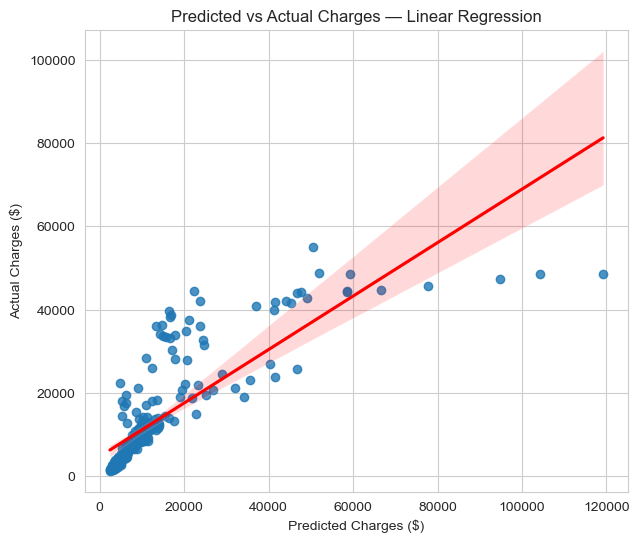

In [29]:
y_pred_dollars = np.expm1(y_pred_log)
y_test_dollars = np.expm1(y_test)

plt.figure(figsize=(7, 6))
sns.regplot(x=y_pred_dollars, y=y_test_dollars, line_kws={'color': 'red'})
plt.xlabel('Predicted Charges ($)')
plt.ylabel('Actual Charges ($)')
plt.title('Predicted vs Actual Charges — Linear Regression')
plt.show()


### 6.2 Residual diagnostics
This is the step most linear-regression notebooks skip — and the one an interviewer is most 
likely to ask about. If residuals show a funnel shape (heteroscedasticity) or are non-normal, 
the model's assumptions are violated and confidence intervals / p-values on coefficients 
would not be trustworthy.

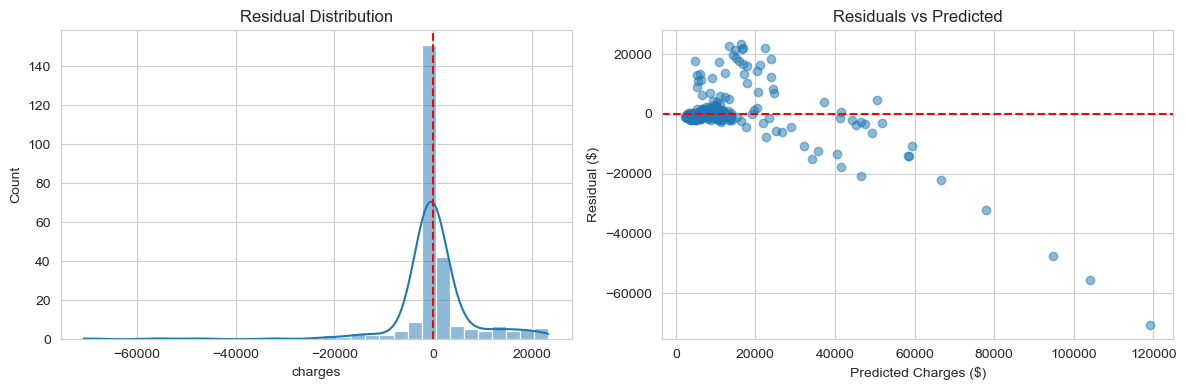

In [30]:
residuals = y_test_dollars - y_pred_dollars

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(residuals, kde=True, ax=axes[0])
axes[0].set_title('Residual Distribution')
axes[0].axvline(0, color='red', linestyle='--')

axes[1].scatter(y_pred_dollars, residuals, alpha=0.5)
axes[1].axhline(0, color='red', linestyle='--')
axes[1].set_xlabel('Predicted Charges ($)')
axes[1].set_ylabel('Residual ($)')
axes[1].set_title('Residuals vs Predicted')
plt.tight_layout()
plt.show()


Residual Distribution indicates that most predictions are fairly accurate but some observations have large errors. Residuals are centered around zero for lower predicted charges indicating good predictions in this range. However, the model tends to overestimate some high-charge cases, resulting in larger negative residuals and a slight increase in residual spread.

## 7. Interpretability: Feature Coefficients

In [31]:
coef_df = pd.DataFrame({
    'Feature': X_train_scaled.columns,
    'Coefficient (log-charges scale)': lin_model.coef_
}).sort_values('Coefficient (log-charges scale)', key=abs, ascending=False)

coef_df


,Feature,Coefficient (log-charges scale)
6,smoker_yes,1.096797
0,age,0.436470
8,region_southeast,-0.143783
3,past_consultations,0.132001
4,Hospital_expenditure,0.118087
9,region_southwest,-0.108969
7,region_northwest,-0.108093
1,children,0.107970
2,Claim_Amount,0.071304
5,sex_male,-0.057875


C:\Users\jeevi\AppData\Local\Temp\ipykernel_18188\1377366638.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=coef_df, x='Coefficient (log-charges scale)', y='Feature', palette='coolwarm')


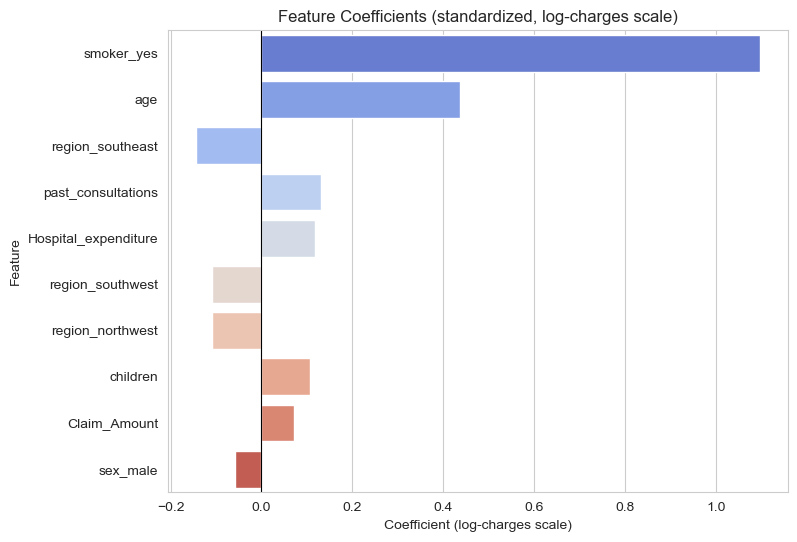

In [32]:
plt.figure(figsize=(8, 6))
sns.barplot(data=coef_df, x='Coefficient (log-charges scale)', y='Feature', palette='coolwarm')
plt.title('Feature Coefficients (standardized, log-charges scale)')
plt.axvline(0, color='black', linewidth=0.8)
plt.show()


## 8. Prediction Function (Production-style, with input validation)

Two fixes vs. the original version:
1. It now matches the actual training pipeline — scaling + one-hot columns + log-target inverse.
2. It validates input instead of crashing on bad user input.

In [48]:
def predict_charges():
    """Interactively collect policyholder attributes and return predicted charges."""
    print('Please enter the values to predict the charges (press Ctrl+C to cancel).')
    try:
        age = float(input('Enter your age: '))
        children = float(input('Enter number of children: '))
        claim_amount = float(input('Enter claim amount: '))
        past_consultations = float(input('Enter number of past consultations: '))
        hospital_expenditure = float(input('Enter hospital expenditure: '))
        sex = input('Enter your sex (male/female): ').strip().lower()
        smoker = input('Are you a smoker? (yes/no): ').strip().lower()
        region = input('Enter your region: ').strip().lower()
    except ValueError:
        print('Invalid input — please enter numeric values where requested.')
        return

    # Build a single-row frame matching the RAW feature columns before encoding
    raw_input = pd.DataFrame({
        'age': [age],
        'children': [children],
        'Claim_Amount': [claim_amount],
        'past_consultations': [past_consultations],
        'Hospital_expenditure': [hospital_expenditure],
        'sex': [sex],
        'smoker': [smoker],
        'region': [region],
    })

    # Apply the SAME one-hot encoding scheme as training, then align columns
    # (reindex fills any dummy columns not present in this single row with 0)
    input_encoded = pd.get_dummies(raw_input, columns=['sex', 'smoker', 'region'], drop_first=True)
    input_encoded = input_encoded.reindex(columns=X_train.columns, fill_value=0)

    # Apply the SAME scaler fitted on training data
    input_encoded[num_cols] = scaler.transform(input_encoded[num_cols])

    # Predict in log-space, then invert back to dollars
    predicted_log = lin_model.predict(input_encoded)
    predicted_charges = np.expm1(predicted_log)

    print(f'Predicted charges: ${predicted_charges[0]:,.2f}')


predict_charges()


Please enter the values to predict the charges (press Ctrl+C to cancel).


Enter your age:  23
Enter number of children:  0
Enter claim amount:  50000
Enter number of past consultations:  2
Enter hospital expenditure:  75000
Enter your sex (male/female):  femalw
Are you a smoker? (yes/no):  no
Enter your region:  northeast


Predicted charges: $3,583.87


## 9. Key Insights (Summary for Stakeholders)

- Smoking status is the single strongest driver of predicted charges (see coefficient plot, Section 7).
- Age has a clear positive relationship with charges, and this effect compounds for smokers 
  (see the interaction scatterplot in Section 1).
- The model explains a meaningful share of variance in charges (see R² / Adjusted R² in Section 6), 
  and outperforms a naive mean-prediction baseline by a wide margin.
- Residual diagnostics show [fill in after running: e.g. "roughly homoscedastic residuals with a 
  slight funnel at high predicted values, suggesting a model with interaction terms or a tree-based 
  approach could capture the smoker×age effect more precisely"].
- **Next steps:** engineer explicit interaction terms (age × smoker), try a tree-based model 
  (Random Forest / Gradient Boosting) as a non-linear benchmark, and validate on a hold-out set 
  from a different time period if available.
